# Research ROI and regions


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

# Outer cell-edge bounds in rotated degrees; select whole cells by their centres.
ROI = {
    "name": "Research ROI",
    "rlat": (-29.115002, 8.505000),
    "rlon": (-30.042221, -6.642220),
    "color": "black",
}

NORTH_AMERICA_EXTENT = (-180, -20, 5, 85)  # west, east, south, north
NORTH_AMERICA_SIZE = (16, 10)
ROI_FIGURE_SIZE = (17, 10)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks/assets/bukovsky/region-masks").is_dir())
REGION_DIR = ROOT / "notebooks/assets/bukovsky/region-masks"
GRID_FILE = ROOT / "outputs/rotated/shared/grid.nc"

sys.path.insert(0, str(ROOT))
from tools.rotated_analysis import crop_grid, edges, perimeter


## Regions and coordinates


In [2]:
# Custom colors are used only for the 31 published regions, in reference-map order.
REGION_COLORS = {
    'ColdNEPacific': '#808080',
    'WarmNEPacific': '#cecece',
    'PacificNW': '#6508bc',
    'PacificSW': '#a600c8',
    'Southwest': '#ffb13b',
    'Mezquital': '#fff77a',
    'NRockies': '#994651',
    'SRockies': '#df7024',
    'GreatBasin': '#896020',
    'NPlains': '#ff177c',
    'CPlains': '#f86aab',
    'SPlains': '#f8b9d5',
    'Prairie': '#b6004b',
    'GreatLakes': '#3400ab',
    'Appalachia': '#00671c',
    'DeepSouth': '#00a4ab',
    'Southeast': '#00dfb1',
    'WarmNWAtlantic': '#b1b1b1',
    'MidAtlantic': '#8fe779',
    'NorthAtlantic': '#36a62c',
    'ColdNWAtlantic': '#676767',
    'EastBoreal': '#00a6ed',
    'WestBoreal': '#00a4aa',
    'EastTaiga': '#b7e7f5',
    'WestTaiga': '#acf5f5',
    'CentralTundra': '#ffffff',
    'WestTundra': '#f0ffff',
    'EastTundra': '#fff5ff',
    'Hudson': '#2c1565',
    'LabradorSea': '#494949',
    'Greenland': '#eb38ed',
}

with xr.open_dataset(REGION_DIR / "PacificNW.nc") as data:
    region_lat = data.lat.values.copy()
    region_lon = (data.lon.values.astype(float)+180)%360-180
region_values = np.full((region_lat.size, region_lon.size), np.nan)
for number, name in enumerate(REGION_COLORS, 1):
    with xr.open_dataset(REGION_DIR / f"{name}.nc") as data:
        region_values[data["mask"].values > 0] = number
region_x, region_y = edges(region_lon), edges(region_lat)
region_cmap = ListedColormap(list(REGION_COLORS.values()))
region_norm = BoundaryNorm(np.arange(0.5, 32.5), 31)

roi_grid = crop_grid(xr.load_dataset(GRID_FILE), ROI)
lon_corners, lat_corners = roi_grid.longitude_edge.values, roi_grid.latitude_edge.values
grid_x, grid_y = roi_grid.rlon_edge.values, roi_grid.rlat_edge.values

# 00 is the single editable ROI entrypoint for notebooks 01, 02 and 03.
(GRID_FILE.parent / "roi.json").write_text(json.dumps(ROI, indent=2)+"\n", encoding="utf-8")
roi_grid.to_netcdf(GRID_FILE.parent / "roi_grid.nc")

grid_lon = (roi_grid.longitude.values+180)%360-180
grid_lat = roi_grid.latitude.values
roi_lon, roi_lat = perimeter(roi_grid)
roi_lon, roi_lat = np.r_[roi_lon, roi_lon[0]], np.r_[roi_lat, roi_lat[0]]
roi_label = f"{ROI['name']}: {roi_grid.rlat.size} × {roi_grid.rlon.size} cells"
roi_handle = Line2D([], [], color=ROI["color"], linewidth=2.5, label=roi_label)

print(roi_label)
print(f"Local positions: rows [0:{roi_grid.rlat.size}], columns [0:{roi_grid.rlon.size}] (stop excluded)")
print(f"rlat cell edges: {grid_y[0]:.6f} to {grid_y[-1]:.6f} degrees")
print(f"rlon cell edges: {grid_x[0]:.6f} to {grid_x[-1]:.6f} degrees")

Research ROI: 418 × 260 cells
Local positions: rows [0:418], columns [0:260] (stop excluded)
rlat cell edges: -29.115002 to 8.505000 degrees
rlon cell edges: -30.042221 to -6.642220 degrees


## North America


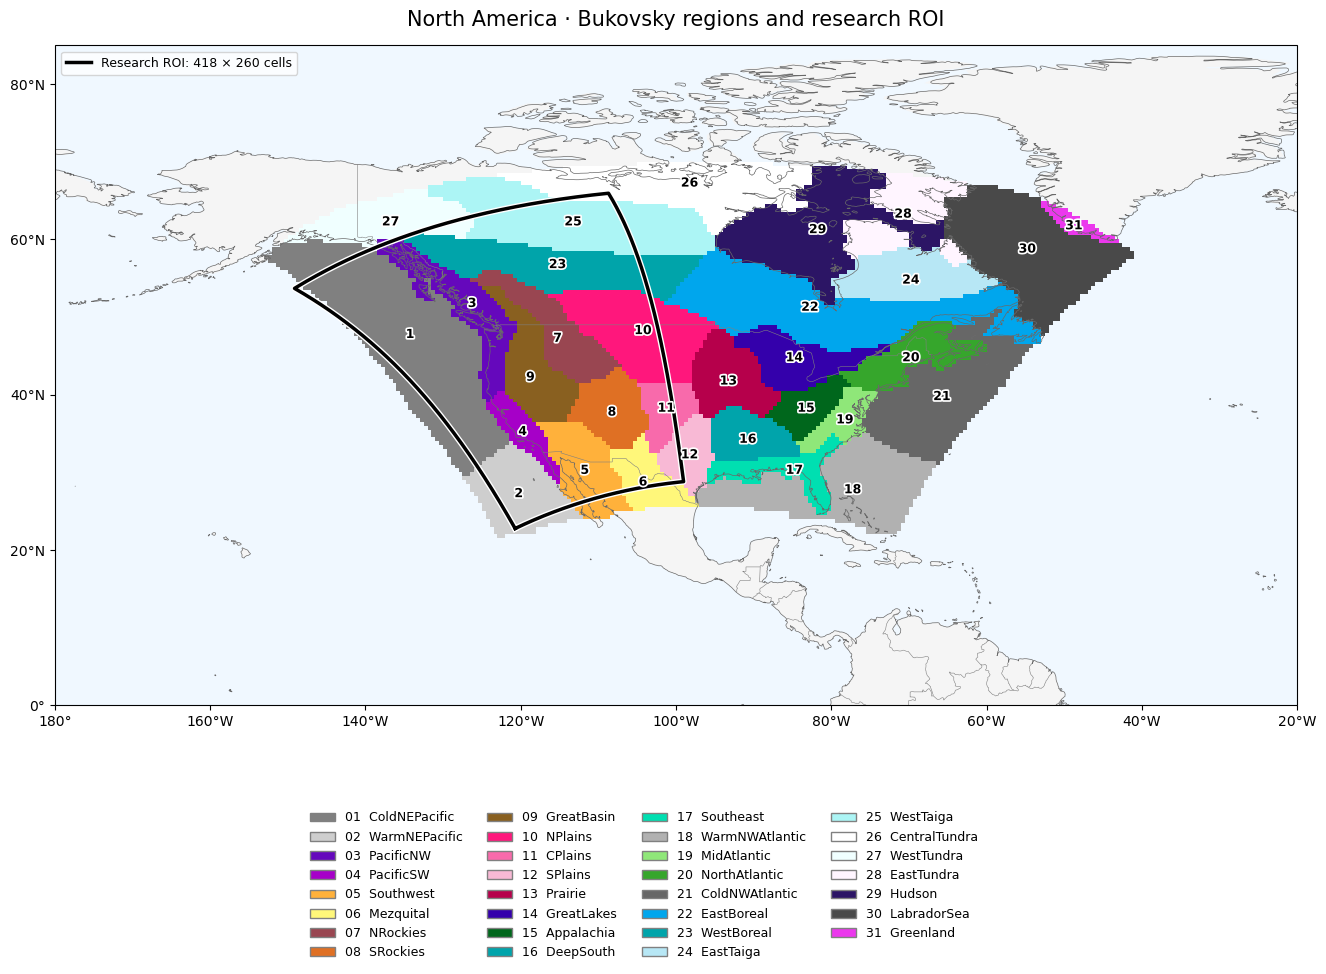

In [3]:
fig, ax = plt.subplots(figsize=NORTH_AMERICA_SIZE, subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent(NORTH_AMERICA_EXTENT, crs=ccrs.PlateCarree())
ax.set_facecolor("aliceblue")
ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="whitesmoke", zorder=0)
ax.pcolormesh(region_x, region_y, np.ma.masked_invalid(region_values),
              cmap=region_cmap, norm=region_norm, transform=ccrs.PlateCarree(),
              shading="flat", edgecolors="face", linewidth=0, rasterized=True)
ax.coastlines("50m", color="dimgray", linewidth=0.5)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="gray", linewidth=0.4)

for number in range(1, 32):
    y, x = np.where(region_values == number)
    distance = ((region_lon[x]-np.median(region_lon[x]))*np.cos(np.deg2rad(region_lat[y])))**2
    distance += (region_lat[y]-np.median(region_lat[y]))**2
    k = distance.argmin()
    ax.text(region_lon[x[k]], region_lat[y[k]], str(number), fontsize=9,
            ha="center", va="center", fontweight="bold", transform=ccrs.PlateCarree(),
            path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
ax.plot(roi_lon, roi_lat, color=ROI["color"], linewidth=2.5,
        transform=ccrs.PlateCarree(),
        path_effects=[pe.withStroke(linewidth=4.5, foreground="white")])
ax.set_title("North America · Bukovsky regions and research ROI", fontsize=15, pad=14)
ax.set_xticks(np.arange(-180, -19, 20), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(0, 81, 20), crs=ccrs.PlateCarree())
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.legend(handles=[roi_handle], loc="upper left", fontsize=9)
region_handles = [Rectangle((0, 0), 1, 1, facecolor=color, edgecolor="gray",
                            label=f"{number:02d}  {name}")
                  for number, (name, color) in enumerate(REGION_COLORS.items(), 1)]
fig.legend(handles=region_handles, loc="lower center", bbox_to_anchor=(0.5, 0.015),
           ncol=4, fontsize=9, frameon=False)
fig.subplots_adjust(left=0.06, right=0.98, top=0.94, bottom=0.28)
plt.show()

## ROI coordinates


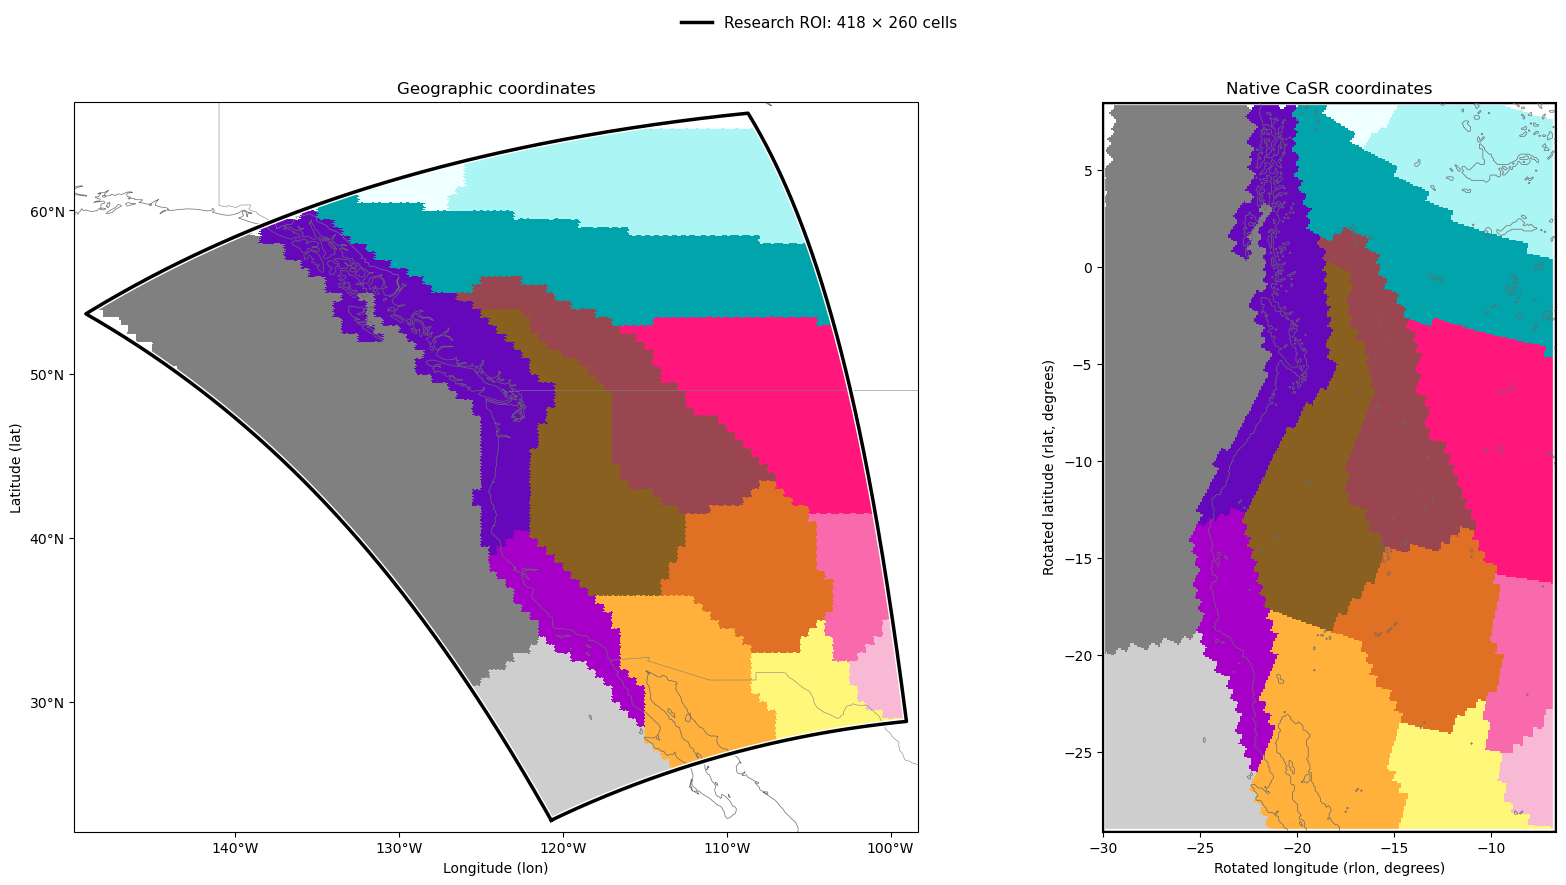

In [4]:
# Assign the category of the original Bukovsky cell containing each CaSR centre.
x = np.searchsorted(region_x, grid_lon, side="right")-1
y = np.searchsorted(region_y, grid_lat, side="right")-1
covered = (x >= 0) & (x < region_lon.size) & (y >= 0) & (y < region_lat.size)
values = region_values[np.clip(y, 0, region_lat.size-1), np.clip(x, 0, region_lon.size-1)]
values = np.ma.masked_where(~covered | ~np.isfinite(values), values)

fig = plt.figure(figsize=ROI_FIGURE_SIZE)
geo = fig.add_axes([0.06, 0.13, 0.50, 0.73], projection=ccrs.PlateCarree())
native = fig.add_axes([0.65, 0.13, 0.30, 0.73])
style = dict(cmap=region_cmap, norm=region_norm, shading="flat",
             edgecolors="face", linewidth=0, rasterized=True)
geo.pcolormesh(lon_corners, lat_corners, values, transform=ccrs.PlateCarree(), **style)
native.pcolormesh(grid_x, grid_y, values, **style)
geo.coastlines("50m", color="dimgray", linewidth=0.5)
geo.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="gray", linewidth=0.4)
native.contour(roi_grid.rlon, roi_grid.rlat, (roi_grid.domain_code.values == 0).astype(float),
               levels=[0.5], colors=["dimgray"], linewidths=0.5)

effects = [pe.withStroke(linewidth=4.5, foreground="white")]
geo.plot(roi_lon, roi_lat, color=ROI["color"], linewidth=2.5,
         transform=ccrs.PlateCarree(), path_effects=effects)
native.add_patch(Rectangle((grid_x[0], grid_y[0]), np.ptp(grid_x), np.ptp(grid_y),
                           fill=False, edgecolor=ROI["color"], linewidth=2.5,
                           path_effects=effects))

west, east = roi_lon.min()-0.7, roi_lon.max()+0.7
south, north = roi_lat.min()-0.7, roi_lat.max()+0.7
geo.set_extent((west, east, south, north), crs=ccrs.PlateCarree())
geo.set_xticks(np.arange(np.ceil(west/10)*10, east, 10), crs=ccrs.PlateCarree())
geo.set_yticks(np.arange(np.ceil(south/10)*10, north, 10), crs=ccrs.PlateCarree())
geo.xaxis.set_major_formatter(LongitudeFormatter())
geo.yaxis.set_major_formatter(LatitudeFormatter())
geo.set(xlabel="Longitude (lon)", ylabel="Latitude (lat)", title="Geographic coordinates")
native.set(xlim=(grid_x[0], grid_x[-1]), ylim=(grid_y[0], grid_y[-1]),
           aspect="equal", xlabel="Rotated longitude (rlon, degrees)",
           ylabel="Rotated latitude (rlat, degrees)", title="Native CaSR coordinates")
fig.legend(handles=[roi_handle], loc="upper center", bbox_to_anchor=(0.5, 0.96),
           fontsize=11, frameon=False)
plt.show()